# L21 · Un agente con herramientas de MCP

*Advanced Topics in Analytics II - Generative AI* · Instructor: Sergio A. Mora Pardo

En [L20](L20-MCPServer.ipynb) distinguimos protocolo, host, cliente, servidor y modelo; construimos los servidores de **ACME** y los probamos sin modelo. Ahora nuestra **aplicación con LangChain** usará Haiku para decidir qué herramientas necesita y redactar la respuesta. `MCPAdapter`, de `langchain.mcp`, adapta las tools de los dos servidores al agente de L13.

El **modelo propone** una llamada, la **aplicación gestiona su ejecución**, el **cliente transmite** la solicitud MCP y el **servidor ejecuta** la operación. La implementación de la consulta sigue en el servidor.

## Antes del código · Una pregunta de principio a fin

Pregunta: **«Soy el cliente C-3307. ¿Cuánto tengo vencido en mi Crédito Libre Inversión?»**

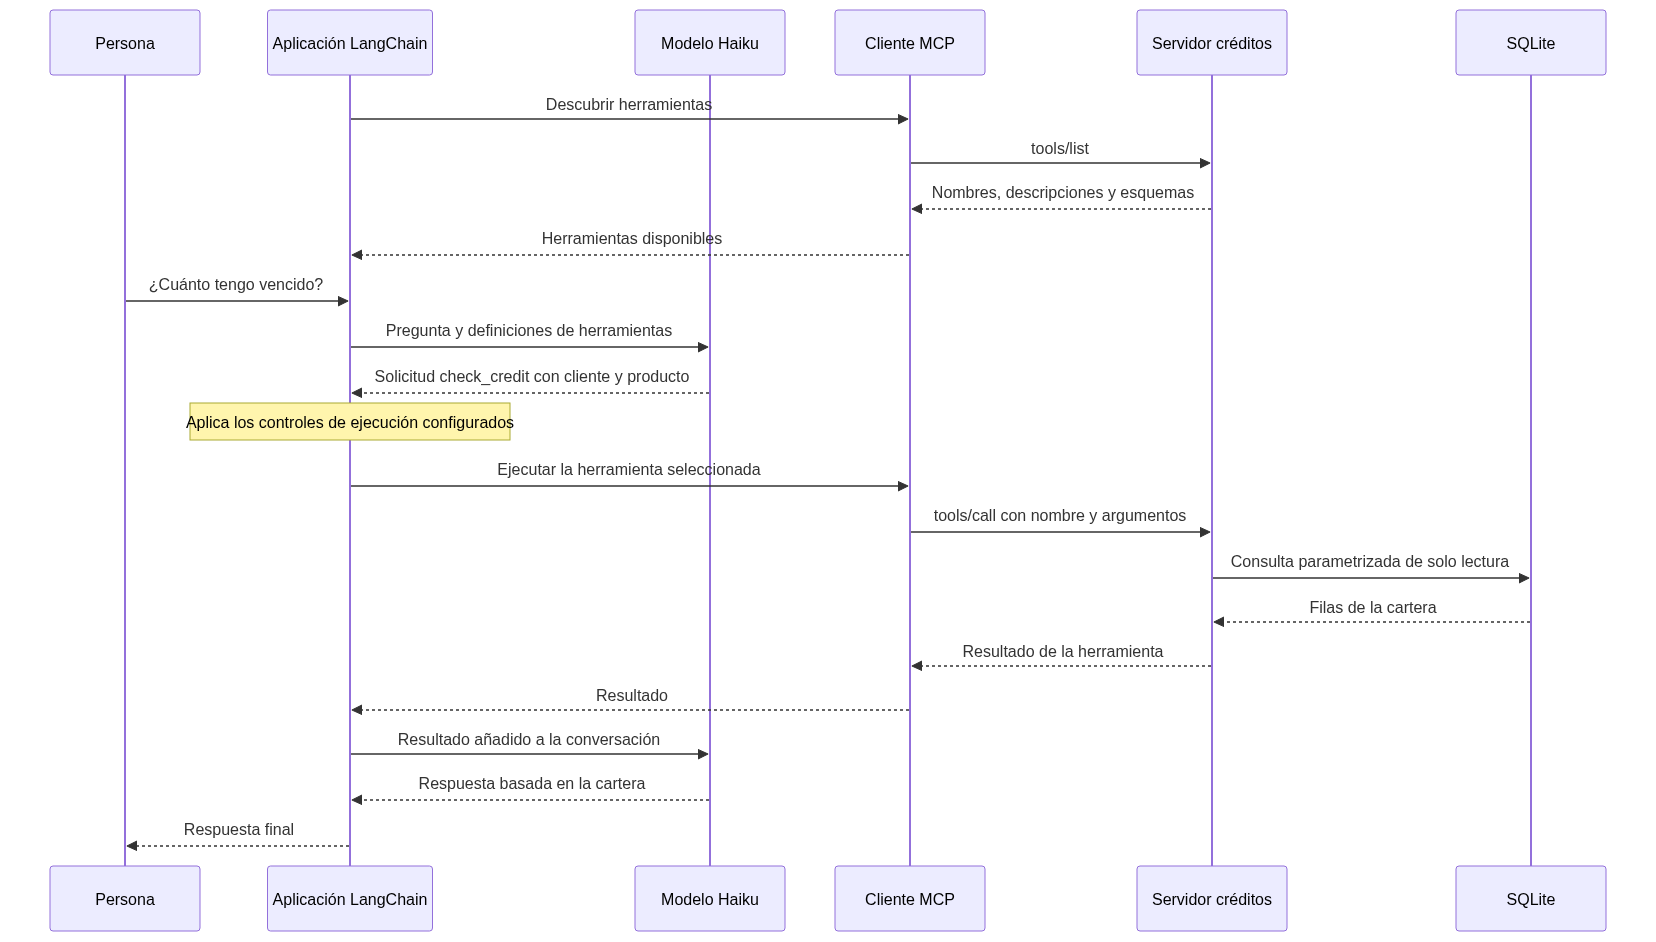

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant P as Persona
    participant A as Aplicación LangChain
    participant M as Modelo Haiku
    participant C as Cliente MCP
    participant S as Servidor créditos
    participant D as SQLite
    A->>C: Descubrir herramientas
    C->>S: tools/list
    S-->>C: Nombres, descripciones y esquemas
    C-->>A: Herramientas disponibles
    P->>A: ¿Cuánto tengo vencido?
    A->>M: Pregunta y definiciones de herramientas
    M-->>A: Solicitud check_credit con cliente y producto
    Note over A: Aplica los controles de ejecución configurados
    A->>C: Ejecutar la herramienta seleccionada
    C->>S: tools/call con nombre y argumentos
    S->>D: Consulta parametrizada de solo lectura
    D-->>S: Filas de la cartera
    S-->>C: Resultado de la herramienta
    C-->>A: Resultado
    A->>M: Resultado añadido a la conversación
    M-->>A: Respuesta basada en la cartera
    A-->>P: Respuesta final
```

</details>

En este notebook descubrimos las herramientas al preparar el agente; no necesitamos volver a descubrirlas en cada turno. La llamada al modelo y los mensajes MCP son intercambios distintos. `create_agent` coordina el ciclo con el modelo y `MCPAdapter` conecta ese ciclo con las tools del servidor.

**Del diagrama al código:** sección 1, descubrimiento y llamada directa; sección 2, decisión del modelo; sección 3, inspección de las llamadas realizadas. La pregunta de la sección 2 añade si puede reestructurar, para necesitar también el servidor de documentos.

Usamos tools de lectura y una base que impide escrituras. «Controlada por el modelo» describe la selección de la herramienta, no autoridad ilimitada: los permisos y las aprobaciones que una aplicación necesite se configuran e implementan, no aparecen automáticamente al conectar MCP.

Referencia del recorrido: [Claude Academy · Clientes MCP](https://academy.claude.com/es/courses/introduction-to-model-context-protocol/mcp-clients).

## 0. Preparación

El modelo de siempre. LangSmith es opcional: con `LANGSMITH_TRACING=true`, las trazas van al proyecto `advancedgenai-l21`, con tu nombre como etiqueta, y un recorrido completo genera **4 trazas**, una por cada `ainvoke` del agente (secciones 2, 4 y 5). Las llamadas a los servidores aparecen dentro de cada traza como pasos de herramienta. La prueba directa de la sección 1 desactiva su traza; el servidor documental desactiva las trazas de su recuperación y el proceso HTTP recibe un entorno mínimo sin claves.

El recorrido realiza **unas 7 llamadas a Claude Haiku**: el agente decide cuántas veces consultar. Repetir celdas consume tokens.

In [ ]:
import os
import sys

from dotenv import find_dotenv, load_dotenv
from langchain_anthropic import ChatAnthropic

# find_dotenv sube por las carpetas hasta encontrar el .env de la raíz
load_dotenv(find_dotenv())

PARTICIPANT = "sergio"  # tu nombre, sin espacios ni tildes
PROJECT = "advancedgenai-l21"  # proyecto de LangSmith de este notebook

model = ChatAnthropic(
    model="claude-haiku-5-5",
    max_tokens=500,
    thinking={"type": "disabled"},
    timeout=60,
    max_retries=2,
)
print("Trazas en LangSmith:", os.getenv("LANGSMITH_TRACING", "false"), "· proyecto:", PROJECT, "· participante:", PARTICIPANT)

## 1. Conectar dos servidores

Sin modelo. `MCPAdapter` recibe la configuración con el mismo formato `mcpServers` que usan Claude Code y Claude Desktop: un nombre por servidor y cómo llegar a él. Una entrada con `command` arranca el módulo como subproceso (stdio), el mismo que usamos en la sección 6 de L20; una con `url` se conecta por HTTP.

`list_tools()` pregunta a cada servidor qué ofrece y convierte cada herramienta MCP en una herramienta de LangChain, con su descripción y su JSON Schema. Con varios servidores, el nombre lleva delante el del servidor: `creditos_check_credit`. `langchain.mcp` está en beta: al importarlo muestra un aviso de que su API puede cambiar.

In [ ]:
import logging

from langchain.mcp import MCPAdapter

logging.getLogger("fastmcp").setLevel(logging.WARNING)  # sin un aviso por cada conexión

servers = {
    "mcpServers": {
        "creditos": {"command": sys.executable, "args": ["-m", "agents.servers.credits"]},
        "documentos": {"command": sys.executable, "args": ["-m", "agents.servers.documents"]},
    }
}
async with MCPAdapter(servers) as adapter:
    tools = await adapter.list_tools()

for mcp_tool in tools:
    print(f"{mcp_tool.name}: {mcp_tool.description.splitlines()[0]}")
    print("    argumentos:", list(mcp_tool.args_schema["properties"]))

Son herramientas de LangChain como las de L13, así que también se pueden probar sin el agente. La interfaz de herramientas de `langchain.mcp` es **asíncrona**: se llama con `ainvoke` y `await`. La prueba directa desactiva su traza para mantener el presupuesto de cuatro trazas del agente.

In [ ]:
from langsmith import tracing_context

check_credit = next(mcp_tool for mcp_tool in tools if mcp_tool.name == "creditos_check_credit")

with tracing_context(enabled=False):  # prueba directa, fuera de las 4 trazas del agente
    direct_credit = await check_credit.ainvoke({"customer": "C-3307", "product": "CLI"})
direct_credit

## 2. El agente

`create_agent` de L13, con las herramientas de los dos servidores y un *system prompt* para el soporte de ACME. Como las herramientas son asíncronas, el agente también se llama con `ainvoke`.

La pregunta necesita **los dos servidores**: el monto vencido sale de la cartera y la regla de reestructuración, de la política de cobranza (**unas 2 o 3 llamadas**: decidir las herramientas, quizá otra consulta, y responder).

In [ ]:
from langchain.agents import create_agent
from langchain_core.messages import HumanMessage

SYSTEM_PROMPT = """\
Eres el asistente de soporte de ACME, una fintech. Responde siempre en español.
Para saldos, montos vencidos y días de mora, consulta siempre la cartera con la herramienta. Di el producto y la cifra en pesos.
Para requisitos, plazos o políticas, busca en los documentos con una pregunta completa y cita cada dato con el formato [archivo, p. N]. Cita una sola página en cada cita.
Si las herramientas no devuelven el dato, dilo y no lo inventes. No prometas aprobaciones.
"""

agent = create_agent(model, tools=tools, system_prompt=SYSTEM_PROMPT)
config = {"tags": [PARTICIPANT], "metadata": {"participant": PARTICIPANT}}
question = (
    "Soy el cliente C-3307. ¿Cuánto tengo vencido en mi Crédito Libre Inversión? "
    "¿Y con cuántos días de mora todavía puedo pedir una reestructuración?"
)

with tracing_context(project_name=PROJECT):
    result = await agent.ainvoke({"messages": [HumanMessage(question)]}, config)

print(result["messages"][-1].text)

## 3. Qué servidor respondió

Sin modelo. Las llamadas a herramientas quedan en los mensajes del agente, como en L13. El prefijo del nombre dice a qué servidor fue cada una:

In [ ]:
for message in result["messages"]:
    if message.type == "ai":
        for call in message.tool_calls:
            server, tool_name = call["name"].split("_", 1)
            print(f"{server} → {tool_name}({call['args']})")

El modelo recibe las definiciones de las herramientas y sus resultados; no necesita conocer la consulta SQL ni el código de embeddings. Si la cartera pasa a PostgreSQL, podemos cambiar la implementación del servidor sin cambiar el agente, **si conservamos el contrato y el significado de sus herramientas**.

En la versión y configuración de `langchain.mcp` utilizadas aquí, las tools abren una **sesión nueva por llamada**. Con stdio eso vuelve a arrancar el proceso; por eso estas tools siguen funcionando fuera del `async with` y el servidor de documentos reconstruye el índice en cada búsqueda. Es comportamiento de este adaptador, no una regla de stdio: un cliente también puede mantener el mismo proceso abierto para varias llamadas.

## 4. Cuando el servidor pregunta: elicitation

**Demo breve; implementación para ampliar.** El flujo básico anterior funciona sin pedir datos adicionales a la persona.

En la sección 7 de L20, el servidor de créditos preguntaba qué crédito quería la persona cuando el cliente tenía varios. Con un agente, ¿quién responde? **La persona, no el modelo.** `langchain.mcp` pausa al agente con un `interrupt` de LangGraph, la aplicación le muestra la pregunta a la persona y el agente sigue con su respuesta. Es el mismo mecanismo de *human-in-the-loop* de la semana 9.

Para pausar y seguir, el agente necesita un **checkpointer** y un `thread_id`, como en L9 (**unas 2 llamadas** en total).

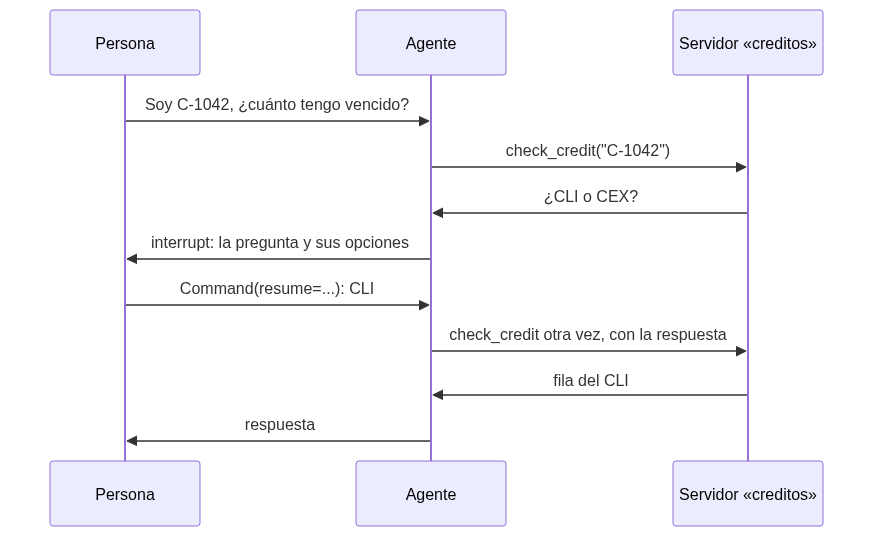

<details><summary>Código Mermaid</summary>

```mermaid
sequenceDiagram
    participant P as Persona
    participant A as Agente
    participant S as Servidor «creditos»
    P->>A: Soy C-1042, ¿cuánto tengo vencido?
    A->>S: check_credit("C-1042")
    S->>A: ¿CLI o CEX?
    A->>P: interrupt: la pregunta y sus opciones
    P->>A: Command(resume=...): CLI
    A->>S: check_credit otra vez, con la respuesta
    S->>A: fila del CLI
    A->>P: respuesta
```

</details>

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command

asking_agent = create_agent(model, tools=tools, system_prompt=SYSTEM_PROMPT, checkpointer=InMemorySaver())
thread = config | {"configurable": {"thread_id": f"{PARTICIPANT}-c-1042-vencido"}}
ambiguous_question = "Soy el cliente C-1042. ¿Cuánto tengo vencido?"

with tracing_context(project_name=PROJECT):
    paused = await asking_agent.ainvoke({"messages": [HumanMessage(ambiguous_question)]}, thread)

[request] = paused["__interrupt__"][0].value["requests"]
print("El servidor pregunta:", request["message"])
print("Opciones:", request["requested_schema"]["properties"]["code"]["enum"])

El agente quedó **pausado** en la llamada a `check_credit`, con su estado guardado en el checkpointer. En una aplicación, aquí se muestra un formulario; en el notebook respondemos nosotros con `Command(resume=...)`: la clave de la pregunta y la respuesta de la persona (`accept` con el dato, `decline` o `cancel`).

In [ ]:
answer = {"action": "accept", "content": {"code": "CLI"}}  # la persona eligió el Crédito Libre Inversión

with tracing_context(project_name=PROJECT):
    resumed = await asking_agent.ainvoke(Command(resume={"responses": {request["key"]: answer}}), thread)

print(resumed["messages"][-1].text)

Al reanudar, la herramienta **vuelve a ejecutarse desde el principio**, ahora con la respuesta. Por eso una herramienta que pregunta no debe hacer nada irreversible antes de la pregunta. Si la persona responde `decline`, el servidor devuelve los dos créditos y el agente responde con ambos.

## 5. El mismo servidor por HTTP

Con **streamable HTTP** el servidor es un proceso que queda encendido y atiende a muchos clientes por una URL. En nuestro ejemplo, el índice se construye una vez por proceso y se reutiliza: permite **centralizar** la recuperación documental para un equipo. Esa reutilización la implementa nuestro servidor; HTTP por sí solo no crea una caché. La celda comprueba que el puerto está libre y que el proceso sigue vivo; si el arranque falla o vence el tiempo de espera, informa el error y limpia el proceso. Aquí lo arrancamos en este equipo, en el puerto 8002; en una empresa viviría en un servidor interno, con autenticación.

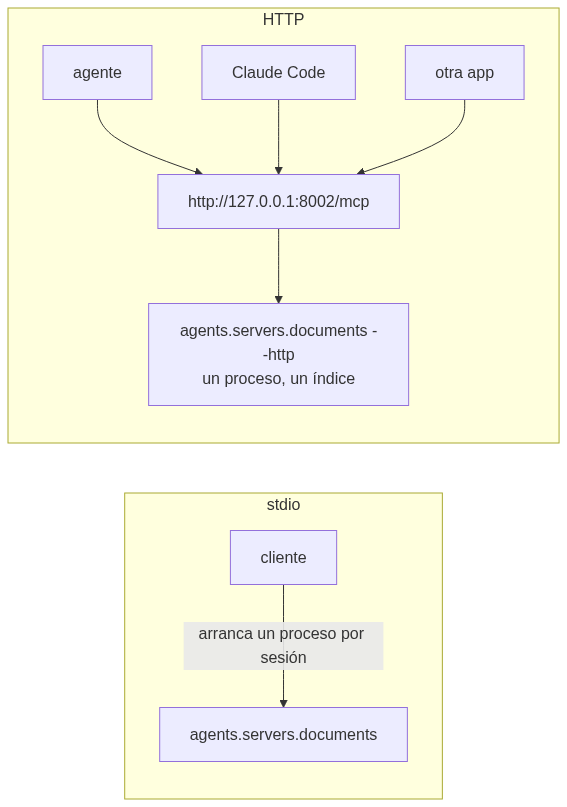

<details><summary>Código Mermaid</summary>

```mermaid
flowchart LR
    subgraph stdio
        C1["cliente"] -->|"arranca un proceso por sesión"| P1["agents.servers.documents"]
    end
    subgraph HTTP
        C2["agente"] --> U["http://127.0.0.1:8002/mcp"]
        C3["Claude Code"] --> U
        C4["otra app"] --> U
        U --> P2["agents.servers.documents --http<br/>un proceso, un índice"]
    end
```

</details>

In [ ]:
import socket
import subprocess
import time

from mcp.client.stdio import get_default_environment

with socket.socket() as probe:
    if probe.connect_ex(("127.0.0.1", 8002)) == 0:
        raise RuntimeError("El puerto 8002 ya está ocupado. Detén el servidor anterior antes de repetir.")

# El mismo entorno mínimo que usa stdio: no hereda claves de API ni variables de LangSmith.
http_server = subprocess.Popen(
    [sys.executable, "-m", "agents.servers.documents", "--http"], env=get_default_environment()
)
try:
    for _ in range(30):
        if http_server.poll() is not None:
            raise RuntimeError("El servidor HTTP terminó antes de estar disponible. Revisa stderr.")
        with socket.socket() as probe:
            if probe.connect_ex(("127.0.0.1", 8002)) == 0:
                break
        time.sleep(1)
    else:
        raise TimeoutError("El servidor HTTP no estuvo disponible en 30 segundos.")
except BaseException:
    if http_server.poll() is None:
        http_server.terminate()
        try:
            http_server.wait(timeout=5)
        except subprocess.TimeoutExpired:
            http_server.kill()
            http_server.wait()
    raise
print("Servidor de documentos en http://127.0.0.1:8002/mcp")

Solo cambia **una entrada** del diccionario de conexiones. El agente, el prompt y las herramientas son los mismos (**unas 2 llamadas**):

In [ ]:
servers["mcpServers"]["documentos"] = {"url": "http://127.0.0.1:8002/mcp"}
async with MCPAdapter(servers) as adapter:
    agent = create_agent(model, tools=await adapter.list_tools(), system_prompt=SYSTEM_PROMPT)

http_question = "¿Qué pasa si mi cuenta está embargada cuando van a desembolsar mi crédito?"
with tracing_context(project_name=PROJECT):
    http_result = await agent.ainvoke({"messages": [HumanMessage(http_question)]}, config)

print(http_result["messages"][-1].text)

Revisa la respuesta: la política de desembolsos **sí** dice qué pasa con una cuenta embargada (página 2, «Desembolsos fallidos»), pero en nuestras pruebas la búsqueda no trajo ese fragmento y el agente respondió que no estaba en los documentos. Mejor eso que inventar: el problema está en la recuperación, no en el transporte. HTTP no cambia la calidad del RAG; las técnicas de L18 sí.

In [ ]:
http_server.terminate()
http_server.wait()
print("Servidor detenido, código", http_server.returncode)

## 6. Los mismos servidores en Claude Code

El archivo [`.mcp.json`](../.mcp.json) de la raíz del repositorio registra los dos servidores para Claude Code, con el mismo formato `mcpServers` de la sección 1:

```json
{
  "mcpServers": {
    "acme-creditos": {"command": "uv", "args": ["run", "--locked", "python", "-m", "agents.servers.credits"]},
    "acme-documentos": {"command": "uv", "args": ["run", "--locked", "python", "-m", "agents.servers.documents"]}
  }
}
```

Al abrir Claude Code en el repositorio, pide aprobar los servidores del proyecto; `/mcp` muestra su estado y sus herramientas. Después se le puede preguntar *«¿Cuánto tiene vencido el cliente C-3307?»* y usa `check_credit`, el **mismo código** que usó el agente de LangChain. Si se pregunta por C-1042 sin decir el producto, Claude Code abre un diálogo con las dos opciones: es la misma elicitation de la sección 4.

## 7. Encontrar servidores: el MCP Registry

**Ampliación opcional.** Puedes pasar a la sección 9 para cerrar el recorrido de clase.

Sin modelo. El [MCP Registry](https://registry.modelcontextprotocol.io) es el catálogo oficial de servidores **públicos**. No guarda código: guarda metadatos (`server.json`) que dicen dónde está el servidor (un paquete de npm, PyPI o Docker, o una URL remota) y cómo arrancarlo. Tiene una API REST que usan los clientes y los *marketplaces*. Si falla la red, el servicio o el formato de respuesta, esta celda informa que se omite la ampliación y permite continuar:

In [ ]:
import httpx

registry_servers = []
try:
    response = httpx.get(
        "https://registry.modelcontextprotocol.io/v0/servers", params={"search": "postgres", "limit": 5}, timeout=15
    )
    response.raise_for_status()
    registry_servers = [item["server"] for item in response.json()["servers"]]
    for server in registry_servers:
        transports = [package["transport"]["type"] for package in server.get("packages", [])]
        transports += [remote["type"] for remote in server.get("remotes", [])]
        print(f"{server['name']} · v{server['version']} · {transports}")
        print("   ", server.get("description", "")[:100])
except (httpx.HTTPError, ValueError, KeyError, TypeError) as error:
    registry_servers = []
    print(f"Registry no disponible ({type(error).__name__}). Esta ampliación es opcional; puedes continuar.")

- El nombre lleva un **espacio de nombres verificado**: `io.github.<usuario>/…` se comprueba con GitHub y un dominio, con DNS. Eso dice **quién** lo publica, no que sea seguro.
- El Registry **no cura** el contenido: antes de conectar un servidor se revisan su origen y sus descripciones, como en la sección 9 de L20.
- **No acepta servidores privados.** Los nuestros viven en el repositorio y se registran en `.mcp.json`; una empresa con muchos servidores internos puede montar un registro privado con la misma API.

## 8. Muchas herramientas: descubrimiento progresivo

**Ampliación opcional.** Profundiza en el costo de proporcionar muchas definiciones al modelo.

Sin modelo. En la configuración de este notebook, cada llamada al modelo lleva el nombre, la descripción y el esquema de **todas** las herramientas conectadas, las use o no. Medimos cuánto ocupan las nuestras:

In [ ]:
import json

for server in ("creditos", "documentos"):
    server_tools = [mcp_tool for mcp_tool in tools if mcp_tool.name.startswith(f"{server}_")]
    definitions = json.dumps(
        [{"name": t.name, "description": t.description, "schema": t.args_schema} for t in server_tools], ensure_ascii=False
    )
    print(f"{server}: {len(server_tools)} herramientas · {len(definitions)} caracteres · unos {len(definitions) // 4} tokens en cada llamada")

Con dos servidores son pocos tokens. Con 30 servidores de 10 herramientas, las definiciones pueden ocupar decenas de miles de tokens **en cada llamada**: más costo, más latencia y un modelo que elige peor entre tantas opciones.

El **descubrimiento progresivo** (*progressive tool discovery*) carga las definiciones solo cuando hacen falta:

- **Claude Code** lo hace solo (*tool search*): al empezar carga solo los nombres de las herramientas y las instrucciones de cada servidor, y trae la definición completa cuando el modelo la necesita.
- **En LangChain**, la forma más simple es conectar solo los servidores que la tarea necesita: un agente de políticas usa `MCPAdapter({"mcpServers": {"documentos": ...}})` y no ve la cartera. Otra opción es darle al agente una herramienta que busque herramientas.
- Una variante más avanzada es *programmatic tool calling* (o *code mode*): el modelo escribe código que llama a las herramientas dentro de un *sandbox*, y solo el resultado final vuelve al contexto.

## 9. Lo que cambia con MCP

| | L13 · `@tool` en el notebook | L20–L21 · servidor MCP |
|---|---|---|
| Implementación | Función local; podría compartirse como biblioteca | Función publicada por un servidor con un contrato MCP |
| Descubrimiento | La aplicación registra las herramientas en su código | El cliente solicita al servidor las definiciones disponibles |
| Reutilización | Requiere integrar la biblioteca o API en cada app | Aplicaciones con clientes compatibles consumen el mismo contrato |
| Cambiar la base de datos | Se modifica la implementación de acceso a datos | Se modifica el servidor; conservar el contrato permite mantener los agentes |
| Credenciales | Las gestiona la aplicación o el servicio al que llama | El servidor puede custodiar las del sistema; el cliente puede necesitar autenticarse ante él |
| Responsabilidad operativa | Mantener código, permisos y dependencias | Además, revisar el servidor y gestionar su proceso o servicio y sus accesos |

MCP no reemplaza a `@tool`: una herramienta que solo usa un agente puede quedarse en el código. Conviene valorar un servidor cuando **varias aplicaciones** necesitan una interfaz común para las mismas capacidades. Debemos comprobar compatibilidad, permisos y resultados en cada cliente; compartir protocolo no garantiza que todos soporten las mismas funciones.

**Qué hace cada capa:** MCP estandariza el intercambio; LangChain organiza el agente; Haiku propone herramientas y redacta; nuestros servidores consultan los datos. El protocolo no mejora por sí solo la calidad del RAG, la exactitud de la respuesta ni los permisos.

## Práctica breve

**Cierre conceptual:** vuelve al diagrama inicial y señala dónde se descubre la herramienta, dónde decide el modelo, dónde se ejecuta el SQL y cómo vuelve el resultado. Explica después qué cambiaría al pasar de stdio a HTTP y qué permanecería igual.

1. Pregunta al agente *«¿Qué productos de crédito tiene ACME?»*. ¿Qué herramientas usa? ¿Usa `list_products` o busca en los documentos?
2. En la sección 5, arranca el servidor una sola vez y ejecuta dos veces la celda de consulta, cambiando la pregunta. Compara cuánto tarda la búsqueda frente a stdio y después detén el servidor.
3. En la sección 4, responde `{"action": "decline"}` en lugar de elegir un crédito. ¿Qué devuelve el servidor y qué responde el agente?
4. Con la tool `overdue_customers` de la práctica de L20, pregunta qué clientes tienen más de 30 días de mora.
5. Busca en el Registry (sección 7) servidores de un tema financiero. ¿Quién los publica? ¿Son paquetes locales o remotos?

## Referencias

**[Claude Academy · Introducción a Model Context Protocol](https://academy.claude.com/es/courses/introduction-to-model-context-protocol)**: [Clientes MCP](https://academy.claude.com/es/courses/introduction-to-model-context-protocol/mcp-clients) inspira el recorrido de descubrimiento, selección, ejecución y respuesta previo al código.

**Building Applications with AI Agents**, Michael Albada, [`langgraph_mcp_client.py`](https://github.com/michaelalbada/BuildingApplicationsWithAIAgents/blob/main/src/frameworks/langgraph_agents/langgraph_mcp_client.py): `MultiServerMCPClient` de `langchain-mcp-adapters` con un servidor stdio y otro HTTP. Ese paquete fue reemplazado por `langchain.mcp` ([guía de migración](https://docs.langchain.com/oss/python/migrate/langchain-mcp-adapters)).

Documentación: [MCP en LangChain](https://docs.langchain.com/oss/python/langchain/mcp) · [Herramientas MCP y elicitation en LangChain](https://docs.langchain.com/oss/python/langchain/mcp/tools) · [Transportes de MCP](https://modelcontextprotocol.io/specification/2025-11-25/basic/transports) · [MCP en Claude Code](https://code.claude.com/docs/en/mcp) · [MCP Registry](https://modelcontextprotocol.io/registry/about) · [Buenas prácticas de clientes: descubrimiento progresivo](https://modelcontextprotocol.io/docs/2026-07-28/develop/clients/client-best-practices)